# Aula 20 — Algoritmo de Huffman na Telemetria do Forno de Torra (Setor 200)

**Disciplina:** ECAA08 — Automática (2026.2) — UNIFEI  
**Projeto:** SCADA-Core Automática / Linha de Produção de Paçoca  
**Equipe:** Grupo 7  

Este notebook implementa e valida o **Algoritmo de Huffman** para compressão sem perdas (*lossless*) da telemetria de alarmes do **Forno de Torra** (Setor 200, CLP 02) enviada ao servidor SCADA.

## 1. Contexto Operacional e Mapeamento de Tags ISA-5.1

O CLP 02 supervisiona o forno contínuo de torra. A cada ciclo de varredura ele envia ao SCADA um vetor de **5 bits de desvio** (bit = 1 indica condição anormal), construído a partir do catálogo ISA-5.1 da Etapa 01:

| Bit | Tag | Proposição (Etapa 01) | Bit = 1 significa |
| :---: | :--- | :---: | :--- |
| 1 | `TT-201` | $t_2$ | Temperatura de torra acima de $160^\circ\text{C}$ |
| 2 | `TS-201` | $\neg c_1$ | **Perda** de chama do queimador |
| 3 | `FS-201` | $\neg f_2$ | **Perda** de fluxo de exaustão |
| 4 | `M-201` | $\neg m_2$ | Esteira do forno **parada** |
| 5 | `M-202` | $\neg m_3$ | Rolos despeliculadores **parados** |

Sem compressão, cada amostra ocupa uma palavra fixa de **5 bits**.

In [1]:
import heapq
import itertools
import math
import random

import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 2. Modelo Probabilístico das Mensagens

Como o forno opera em regime estável durante a maior parte do tempo, o estado nominal (`00000`) domina a telemetria. Os desvios são raros e, por isso, devem receber os códigos mais longos.

> As probabilidades abaixo são **estimativas de projeto** do grupo (hipótese de modelagem), não medições de campo.

In [2]:
# Vetor de estado: [TT-201, TS-201, FS-201, M-201, M-202]  (1 = desvio)
state_probabilities = {
    '00000': 0.920,  # Operação nominal estável
    '00010': 0.040,  # Esteira do forno parada (M-201)
    '00100': 0.020,  # Perda de fluxo de exaustão (FS-201)
    '10000': 0.010,  # Sobretemperatura (TT-201 > 160 °C)
    '01000': 0.007,  # Perda de chama do queimador (TS-201)
    '00001': 0.003,  # Rolos despeliculadores parados (M-202)
}
assert abs(sum(state_probabilities.values()) - 1.0) < 1e-12, "As probabilidades devem somar 1"

descricao = {
    '00000': 'Operação nominal', '00010': 'Esteira parada (M-201)',
    '00100': 'Perda de exaustão (FS-201)', '10000': 'Sobretemperatura (TT-201)',
    '01000': 'Perda de chama (TS-201)', '00001': 'Rolos parados (M-202)',
}
df_probs = pd.DataFrame({
    'Vetor de Estado': list(state_probabilities.keys()),
    'Condição': [descricao[s] for s in state_probabilities],
    'Probabilidade': list(state_probabilities.values()),
})
df_probs['Porcentagem (%)'] = df_probs['Probabilidade'] * 100
df_probs

,Vetor de Estado,Condição,Probabilidade,Porcentagem (%)
0,00000,Operação nominal,0.920,92.0
1,00010,Esteira parada (M-201),0.040,4.0
2,00100,Perda de exaustão (FS-201),0.020,2.0
3,10000,Sobretemperatura (TT-201),0.010,1.0
4,01000,Perda de chama (TS-201),0.007,0.7
5,00001,Rolos parados (M-202),0.003,0.3


## 3. Construção da Árvore de Huffman e Geração dos Códigos

Usamos uma fila de prioridade (*min-heap*). Um contador sequencial desempata pesos iguais, tornando a árvore **determinística** (importante para que CLP e servidor construam exatamente o mesmo dicionário).

In [3]:
class HuffmanNode:
    def __init__(self, symbol=None, freq=0.0, left=None, right=None):
        self.symbol, self.freq, self.left, self.right = symbol, freq, left, right

def build_huffman_tree(probabilities):
    counter = itertools.count()                      # desempate determinístico
    heap = [(p, next(counter), HuffmanNode(symbol=s, freq=p)) for s, p in probabilities.items()]
    heapq.heapify(heap)
    while len(heap) > 1:
        p1, _, a = heapq.heappop(heap)
        p2, _, b = heapq.heappop(heap)
        print(f"Une {a.symbol or 'nó interno'} ({p1:.3f}) + {b.symbol or 'nó interno'} ({p2:.3f}) -> peso {p1 + p2:.3f}")
        merged = HuffmanNode(freq=p1 + p2, left=b, right=a)   # ramo mais provável = bit 0
        heapq.heappush(heap, (merged.freq, next(counter), merged))
    return heap[0][2]

def generate_codes(node, prefix="", codes=None):
    codes = {} if codes is None else codes
    if node.symbol is not None:
        codes[node.symbol] = prefix or "0"
    else:
        generate_codes(node.left, prefix + "0", codes)
        generate_codes(node.right, prefix + "1", codes)
    return codes

tree_root = build_huffman_tree(state_probabilities)
huffman_codes = generate_codes(tree_root)

print("\n--- Códigos de Huffman ---")
for sym, code in sorted(huffman_codes.items(), key=lambda kv: len(kv[1])):
    print(f"{sym} | {descricao[sym]:<28} | P = {state_probabilities[sym]:.3f} | código {code:>5} ({len(code)} bits)")

# Verificações formais: propriedade de prefixo e desigualdade de Kraft
codes = list(huffman_codes.values())
is_prefix_free = not any(a != b and b.startswith(a) for a in codes for b in codes)
kraft = sum(2 ** -len(c) for c in codes)
print(f"\nCódigo livre de prefixo: {is_prefix_free} | Soma de Kraft = {kraft:.4f} (deve ser 1 para árvore cheia)")

Une 00001 (0.003) + 01000 (0.007) -> peso 0.010
Une 10000 (0.010) + nó interno (0.010) -> peso 0.020
Une 00100 (0.020) + nó interno (0.020) -> peso 0.040
Une 00010 (0.040) + nó interno (0.040) -> peso 0.080
Une nó interno (0.080) + 00000 (0.920) -> peso 1.000

--- Códigos de Huffman ---
00000 | Operação nominal             | P = 0.920 | código     0 (1 bits)
00010 | Esteira parada (M-201)       | P = 0.040 | código    11 (2 bits)
00100 | Perda de exaustão (FS-201)   | P = 0.020 | código   101 (3 bits)
10000 | Sobretemperatura (TT-201)    | P = 0.010 | código  1001 (4 bits)
01000 | Perda de chama (TS-201)      | P = 0.007 | código 10000 (5 bits)
00001 | Rolos parados (M-202)        | P = 0.003 | código 10001 (5 bits)

Código livre de prefixo: True | Soma de Kraft = 1.0000 (deve ser 1 para árvore cheia)


## 4. Simulação de Transmissão: 10.000 Amostras

O CLP 02 amostra o forno a cada 100 ms. Simulamos 10.000 varreduras (≈ 16,7 min de operação).

In [4]:
NUM_SAMPLES = 10_000
random.seed(42)
telemetry_stream = random.choices(list(state_probabilities), weights=list(state_probabilities.values()), k=NUM_SAMPLES)

raw_bitstream = "".join(telemetry_stream)                                   # 5 bits/amostra
compressed_bitstream = "".join(huffman_codes[s] for s in telemetry_stream)  # Huffman

raw_bits, comp_bits = len(raw_bitstream), len(compressed_bitstream)
print(f"Amostras processadas : {NUM_SAMPLES:,}")
print(f"Tamanho bruto        : {raw_bits:,} bits ({raw_bits/8/1024:.2f} KB)")
print(f"Tamanho comprimido   : {comp_bits:,} bits ({comp_bits/8/1024:.2f} KB)")
print(f"Redução de volume    : {100 * (1 - comp_bits / raw_bits):.2f}%")

Amostras processadas : 10,000
Tamanho bruto        : 50,000 bits (6.10 KB)
Tamanho comprimido   : 11,535 bits (1.41 KB)
Redução de volume    : 76.93%


## 5. Decodificação e Validação Sem Perdas

O servidor SCADA percorre a árvore bit a bit: `0` desce à esquerda, `1` desce à direita, e ao chegar numa folha emite o símbolo e volta à raiz. Como o código é livre de prefixo, a decodificação é determinística e custa $O(k)$ por símbolo ($k \le 5$).

In [5]:
def decode_huffman(bitstream, root, max_symbols=None):
    out, node = [], root
    for bit in bitstream:
        node = node.left if bit == '0' else node.right
        if node.symbol is not None:
            out.append(node.symbol)
            node = root
            if max_symbols is not None and len(out) == max_symbols:
                break
    return out

decoded = decode_huffman(compressed_bitstream, tree_root)
print("Validação lossless:", "✅ recuperação 100% fiel" if decoded == telemetry_stream else "❌ ERRO de integridade")

Validação lossless: ✅ recuperação 100% fiel


## 6. Quadro de Transmissão com CRC-16

O servidor precisa saber **onde o payload termina**: o preenchimento (*padding*) até completar o último byte seria decodificado como símbolos `0` (= nominal) espúrios. Por isso o quadro leva, além do formato do enunciado (Header, Length, Payload, CRC-16), um campo **Count** com o número de amostras:

| Header (8 b) | Count (8 b) | Length (8 b) | Payload Huffman | CRC-16 (16 b) |
| :---: | :---: | :---: | :---: | :---: |
| `0xA5` | nº de amostras | bytes do payload | bits codificados + padding | CRC-16/CCITT-FALSE |

Cada quadro agrupa **100 varreduras (10 s)**.

In [6]:
def crc16_ccitt(data: bytes, poly=0x1021, init=0xFFFF) -> int:
    crc = init
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ poly) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc

def bits_to_bytes(bits: str) -> bytes:
    bits += '0' * (-len(bits) % 8)
    return bytes(int(bits[i:i+8], 2) for i in range(0, len(bits), 8))

def bytes_to_bits(data: bytes) -> str:
    return ''.join(f'{b:08b}' for b in data)

def encode_frame(samples, codes):
    payload = bits_to_bytes(''.join(codes[s] for s in samples))
    body = bytes([0xA5, len(samples), len(payload)]) + payload
    return body + crc16_ccitt(body).to_bytes(2, 'big')

def decode_frame(frame: bytes, root):
    body, crc_rx = frame[:-2], int.from_bytes(frame[-2:], 'big')
    if crc16_ccitt(body) != crc_rx or body[0] != 0xA5:
        return None                                   # quadro corrompido: descartar
    count, length = body[1], body[2]
    return decode_huffman(bytes_to_bits(body[3:3 + length]), root, max_symbols=count)

QUADRO = 100
frames = [encode_frame(telemetry_stream[i:i+QUADRO], huffman_codes) for i in range(0, NUM_SAMPLES, QUADRO)]
raw_frame_bytes = 3 + math.ceil(QUADRO * 5 / 8) + 2          # mesmo envelope, payload fixo de 5 bits

recovered = [s for f in frames for s in decode_frame(f, tree_root)]
print(f"Quadros: {len(frames)} | tamanho médio: {sum(map(len, frames))/len(frames):.1f} B "
      f"(bruto equivalente: {raw_frame_bytes} B)")
print("Round-trip por quadros:", "✅ OK" if recovered == telemetry_stream else "❌ FALHA")

# Injeção de ruído: inverte 1 bit do payload do primeiro quadro
corrompido = bytearray(frames[0]); corrompido[4] ^= 0b00000100
print("Quadro com 1 bit invertido ->", "descartado pelo CRC-16 ✅" if decode_frame(bytes(corrompido), tree_root) is None else "ACEITO ❌")

Quadros: 100 | tamanho médio: 19.9 B (bruto equivalente: 68 B)
Round-trip por quadros: ✅ OK
Quadro com 1 bit invertido -> descartado pelo CRC-16 ✅


## 7. Análise Teórica e Gráficos

Comparação com o limite da **Entropia de Shannon** $H(S) = -\sum P(s_i)\log_2 P(s_i)$. O comprimento médio $L$ de qualquer código de prefixo satisfaz $H \le L < H + 1$.

Entropia de Shannon H(S)        : 0.5510 bits/símbolo
Comprimento médio L (Huffman)   : 1.1500 bits/símbolo
Formato fixo                    : 5.0000 bits/símbolo
Eficiência do código (H/L)      : 47.91%
Redução teórica de banda        : 77.00%


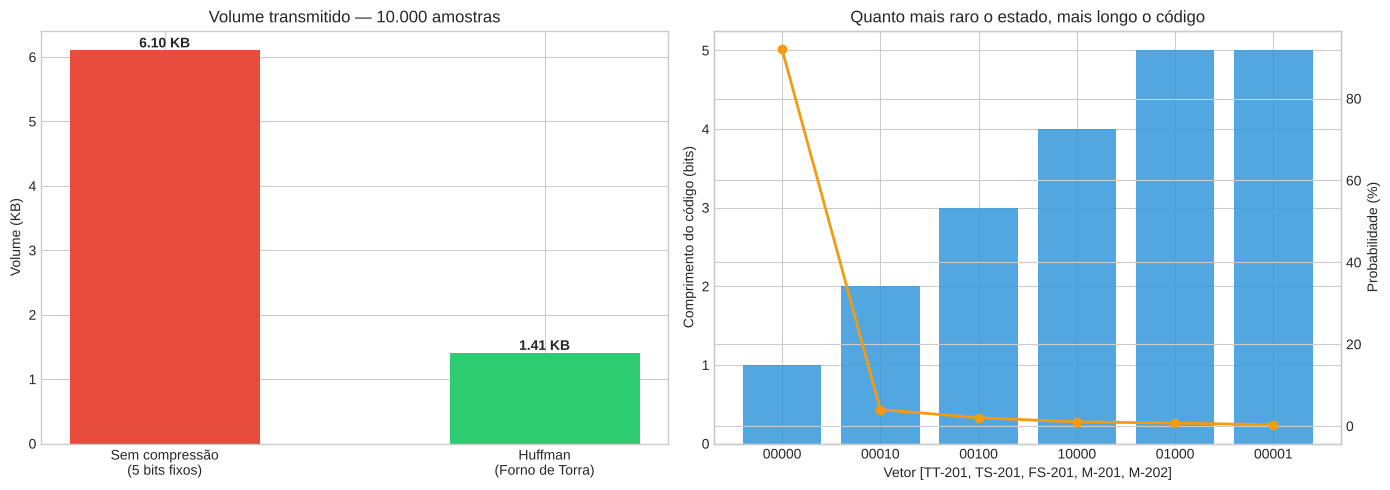

In [7]:
entropy = -sum(p * math.log2(p) for p in state_probabilities.values())
avg_len = sum(p * len(huffman_codes[s]) for s, p in state_probabilities.items())

print(f"Entropia de Shannon H(S)        : {entropy:.4f} bits/símbolo")
print(f"Comprimento médio L (Huffman)   : {avg_len:.4f} bits/símbolo")
print(f"Formato fixo                    : 5.0000 bits/símbolo")
print(f"Eficiência do código (H/L)      : {100 * entropy / avg_len:.2f}%")
print(f"Redução teórica de banda        : {100 * (1 - avg_len / 5):.2f}%")
assert entropy <= avg_len < entropy + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
vals = [raw_bits / 8 / 1024, comp_bits / 8 / 1024]
bars = ax1.bar(['Sem compressão\n(5 bits fixos)', 'Huffman\n(Forno de Torra)'], vals, color=['#e74c3c', '#2ecc71'], width=0.5)
for b in bars:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height(), f'{b.get_height():.2f} KB', ha='center', va='bottom', fontweight='bold')
ax1.set_ylabel('Volume (KB)'); ax1.set_title('Volume transmitido — 10.000 amostras')

states = list(state_probabilities)
ax2.bar(states, [len(huffman_codes[s]) for s in states], color='#3498db', alpha=.85)
ax2.set_xlabel('Vetor [TT-201, TS-201, FS-201, M-201, M-202]'); ax2.set_ylabel('Comprimento do código (bits)')
tw = ax2.twinx(); tw.plot(states, [state_probabilities[s] * 100 for s in states], color='#f39c12', marker='o', lw=2)
tw.set_ylabel('Probabilidade (%)'); ax2.set_title('Quanto mais raro o estado, mais longo o código')
plt.tight_layout(); plt.show()

## 8. Conclusões

1. **Compressão sem perdas validada:** a sequência decodificada é idêntica à original, tanto no fluxo contínuo quanto em quadros com CRC-16.
2. **Ganho real, mas com limite estrutural:** $L \approx 1{,}15$ bits contra $H(S) \approx 0{,}55$ bits, ou seja, redução de cerca de 77% sobre os 5 bits fixos. A eficiência $H/L$ é de apenas ~48% porque o estado nominal tem $P = 0{,}92$ e Huffman não pode gastar menos de 1 bit por símbolo; para se aproximar de $H$ seria preciso codificar **blocos** de amostras consecutivas (extensão da fonte).
3. **Segurança:** estados críticos (perda de chama, sobretemperatura) recebem os códigos **mais longos**, mas sua detecção continua imediata — a compressão atua só no transporte, e o intertravamento do forno (SIS) continua executando no CLP, sem depender do link.
4. **Resiliência:** um único bit invertido no payload é rejeitado pelo CRC-16, e o SCADA mantém o último estado válido com flag de diagnóstico.